# Train and test your Image Classifier RFHOG

We teach a Random Forest to recognize **empty** and **occupied** mailbox images.
We use **80% of the images for training** and keep **20% for testing**. The model never learns from the test images.

Put your images in two folders:
```
mailbox_dataset/
├── empty/
└── occupied/
```
Run the cells from top to bottom. Change `DATASET_DIR` below to your own folder.
If packages are missing, run `%pip install numpy pandas matplotlib pillow scikit-image scikit-learn joblib` in a new notebook cell.

Collect varied images: different letters, packages, positions and lighting. Avoid putting identical or almost identical photos in both sets. Photos from the same delivery can look very similar; for a stronger real-world check, test on separate deliveries.


In [2]:
# Load the tools we need to read images, train the model and draw charts.
from pathlib import Path
import json
import math
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split


In [3]:
# Change this path to the folder containing empty/ and occupied/.
DATASET_DIR = Path("/Volumes/media/mailbox_dataset")
MODEL_OUT = Path("/Volumes/media/image_classifier_rfhog/mailbox_rfhog.joblib")
METADATA_OUT = Path("/Volumes/media/image_classifier_rfhog/mailbox_rfhog_metadata.json")

TEST_SIZE = 0.20  # Keep 20% of images for testing.
RANDOM_STATE = 42  # Use the same split when running the notebook again.
N_ESTIMATORS = 400  # Number of decision trees in our Random Forest.

HOG_SIZE = (160, 120)  # width, height
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)


## 1. Turn each image into numbers

The model needs numbers rather than image files. We describe the colors, brightness and edges in each image. **HOG** describes shapes and edges. Keep these settings the same when using the model in the Home Assistant App.


In [4]:
def extract_features(image_path: str) -> np.ndarray:
    with Image.open(image_path) as im:
        rgb = im.convert("RGB").resize((320, 240))
        arr = np.asarray(rgb, dtype=np.uint8)
        feats = []

        # Count how often different amounts of red, green and blue appear.
        for c in range(3):
            hist, _ = np.histogram(arr[:, :, c], bins=32, range=(0, 256), density=True)
            feats.extend(hist.tolist())

        # Describe the colors in another way: hue, saturation and brightness.
        hsv = np.asarray(rgb.convert("HSV"), dtype=np.uint8)
        for c in range(3):
            hist, _ = np.histogram(hsv[:, :, c], bins=32, range=(0, 256), density=True)
            feats.extend(hist.tolist())

        # Count the light and dark shades in a black-and-white version.
        gray = np.asarray(rgb.convert("L"), dtype=np.uint8)
        hist, _ = np.histogram(gray, bins=32, range=(0, 256), density=True)
        feats.extend(hist.tolist())

        # Add the average brightness/color and how much they vary.
        feats.extend(arr.mean(axis=(0, 1)).tolist())
        feats.extend(arr.std(axis=(0, 1)).tolist())
        feats.append(float(gray.mean()))
        feats.append(float(gray.std()))

        # Estimate how many edges are present in the image.
        dx = np.abs(np.diff(gray.astype(np.int16), axis=1))
        dy = np.abs(np.diff(gray.astype(np.int16), axis=0))
        edge_density = float((dx > 20).mean() + (dy > 20).mean()) / 2.0
        feats.append(edge_density)

        # HOG describes local edges and shapes, which can help detect mail.
        hog_gray = np.asarray(
            rgb.convert("L").resize(HOG_SIZE),
            dtype=np.float32
        ) / 255.0

        hog_features = hog(
            hog_gray,
            orientations=HOG_ORIENTATIONS,
            pixels_per_cell=HOG_PIXELS_PER_CELL,
            cells_per_block=HOG_CELLS_PER_BLOCK,
            block_norm="L2-Hys",
            feature_vector=True,
        )

        feats.extend(hog_features.tolist())

    return np.asarray(feats, dtype=np.float32)


## 2. Find the images and extract their features


In [5]:
extensions = {".jpg", ".jpeg", ".png", ".webp"}
rows = []
for label in ["empty", "occupied"]:
    folder = DATASET_DIR / label
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing folder: {folder}. Check DATASET_DIR above.")
    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.suffix.lower() in extensions:
            rows.append({"path": path, "label": label})

# Each row stores an image filename and its correct class.
df = pd.DataFrame(rows, columns=["path", "label"])
class_counts = df["label"].value_counts().reindex(["empty", "occupied"], fill_value=0)
print("Images per class:")
print(class_counts)
print(f"Total images: {len(df)}")
if (class_counts < 2).any():
    raise ValueError("Add at least 2 images to EACH folder. Many more images are needed for a useful test.")
# Both sets need room for at least one image of each class.
n_test = math.ceil(len(df) * TEST_SIZE)
if not 0 < TEST_SIZE < 1 or n_test < 2 or len(df) - n_test < 2:
    raise ValueError("The split is too small for both classes. Add more images or adjust TEST_SIZE.")


Images per class:
label
empty       310
occupied    162
Name: count, dtype: int64
Total images: 472


In [6]:
# One row of X contains the numbers describing one image.
# y contains the correct class (empty or occupied) for each row.
X = np.vstack([extract_features(str(p)) for p in df["path"]])
y = df["label"].to_numpy()
print("Feature matrix:", X.shape)
print("Feature count per image:", X.shape[1])


Feature matrix: (472, 9809)
Feature count per image: 9809


In [7]:
y

array(['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty',
       'empty', 'emp

## 3. Split into training and test sets

`stratify` keeps roughly the same balance of empty and occupied images in both sets. We split the row numbers so we can also show the filenames later.


In [13]:
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f"Training images: {len(y_train)}")
print(f"Test images: {len(y_test)}")
print(pd.DataFrame({
    "Training": pd.Series(y_train).value_counts(),
    "Test": pd.Series(y_test).value_counts(),
}).fillna(0).astype(int))


Training images: 377
Test images: 95
          Training  Test
empty          248    62
occupied       129    33


## 4. Train the model

Only the training images are passed to `fit`. The test images stay unseen.


In [14]:
model = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1,
    min_samples_leaf=1,
    max_features="sqrt",
)
model.fit(X_train, y_train)
print("Training finished!")


Training finished!


## 5. Test on the unseen images

**Accuracy** is the fraction of test images classified correctly. A small test set can give a misleading score. The confusion matrix shows which mistakes occurred; a **false empty** means mail was present but missed.


Test accuracy: 100.0% (95/95 images correct)
              precision    recall  f1-score   support

       empty      1.000     1.000     1.000        62
    occupied      1.000     1.000     1.000        33

    accuracy                          1.000        95
   macro avg      1.000     1.000     1.000        95
weighted avg      1.000     1.000     1.000        95



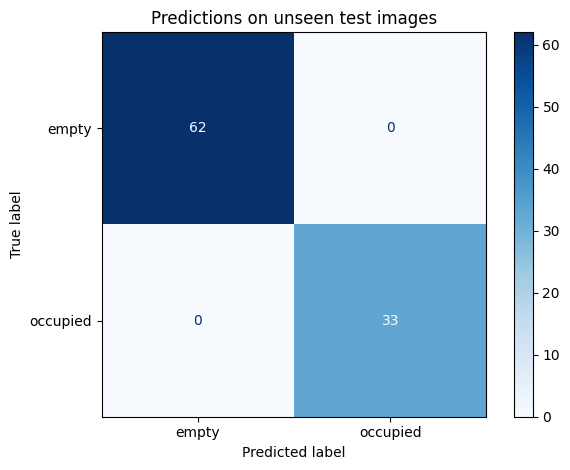

False empty (mail missed): 0
False occupied (false alarm): 0


In [15]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
correct = int((y_test == y_pred).sum())
print(f"Test accuracy: {accuracy:.1%} ({correct}/{len(y_test)} images correct)")
print(classification_report(y_test, y_pred, labels=["empty", "occupied"], digits=3, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=["empty", "occupied"])
ConfusionMatrixDisplay(cm, display_labels=["empty", "occupied"]).plot(cmap="Blues")
plt.title("Predictions on unseen test images")
plt.tight_layout()
plt.show()
print("False empty (mail missed):", int(((y_test == "occupied") & (y_pred == "empty")).sum()))
print("False occupied (false alarm):", int(((y_test == "empty") & (y_pred == "occupied")).sum()))


False empty — mail missed: 1


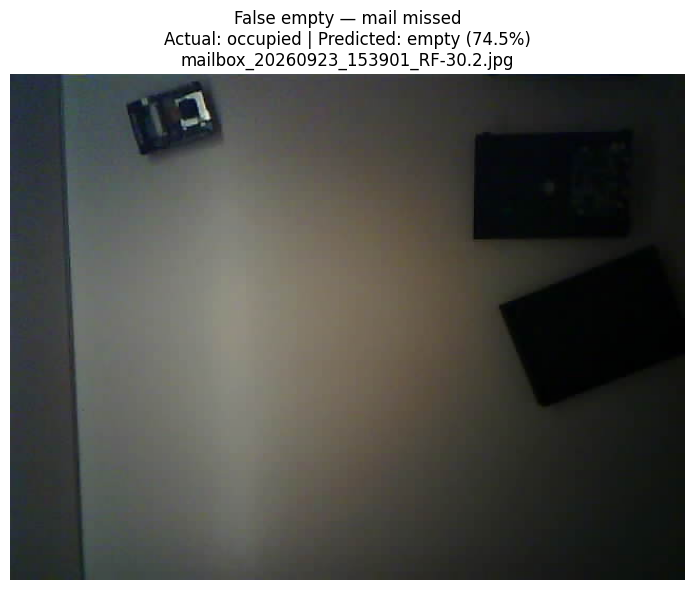

File: /Volumes/media/mailbox_dataset/occupied/mailbox_20260923_153901_RF-30.2.jpg
False occupied — false alarm: 0
No images to show.


In [9]:
# Show test images where the model made a mistake.
from PIL import Image
import matplotlib.pyplot as plt

def show_mistakes(actual_class, predicted_class, title):
    # Find test images with this type of mistake.
    mistakes = np.flatnonzero(
        (y_test == actual_class) & (y_pred == predicted_class)
    )

    print(f"{title}: {len(mistakes)}")

    if len(mistakes) == 0:
        print("No images to show.")
        return

    for i in mistakes:
        # test_idx connects each test sample to its original image.
        image_path = df.iloc[test_idx[i]]["path"]

        # Get the probability assigned to the predicted class.
        class_column = list(model.classes_).index(predicted_class)
        probability = model.predict_proba(X_test[i:i + 1])[0, class_column]

        with Image.open(image_path) as image:
            plt.figure(figsize=(8, 6))
            plt.imshow(image.convert("RGB"))
            plt.title(
                f"{title}\n"
                f"Actual: {actual_class} | Predicted: {predicted_class} "
                f"({probability:.1%})\n"
                f"{image_path.name}"
            )
            plt.axis("off")
            plt.tight_layout()
            plt.show()

        print(f"File: {image_path}")


# Mail is present, but the model says empty.
show_mistakes("occupied", "empty", "False empty — mail missed")

# The mailbox is empty, but the model says occupied.
show_mistakes("empty", "occupied", "False occupied — false alarm")

## 6. See the probabilities for every test image

The first chart shows **both class probabilities for each image**: blue for empty and orange for occupied. The two values add up to 100%. The labels below the chart are the **actual** classes.

The second chart compares the probability of **occupied** for truly empty images (blue) and truly occupied images (orange). Ideally, blue points sit near 0% and orange points near 100%. If the groups overlap horizontally, some images are hard to distinguish. An X marks an incorrect prediction.

These are model probability estimates, not a measurement of how full the mailbox is, and not a guarantee that the prediction is correct. Repeatedly adjusting the model based on this test set makes it less independent; use fresh images for a final check.


 Sample                                                                    File   Actual Predicted P(empty) P(occupied)
      1 occupied/mailbox_20260909_134712_SSIM-79.64_DIFF-6.21_CHANGED-45.32.jpg occupied  occupied    22.5%       77.5%
      2     empty/mailbox_20260909_124155_SSIM-93.45_DIFF-4.1_CHANGED-25.78.jpg    empty     empty    95.5%        4.5%
      3                                empty/mailbox_20261001_105856_RF-8.2.jpg    empty     empty    98.8%        1.2%
      4                            occupied/mailbox_20260923_213404_RF-77.5.jpg occupied  occupied     9.8%       90.2%
      5                               empty/mailbox_20260926_190131_RF-15.2.jpg    empty     empty    98.0%        2.0%
      6                                empty/mailbox_20260921_171702_RF-7.2.jpg    empty     empty    93.0%        7.0%
      7                               empty/mailbox_20260918_134126_RF-10.5.jpg    empty     empty    97.8%        2.2%
      8   occupied/mailbox_20260909_1258

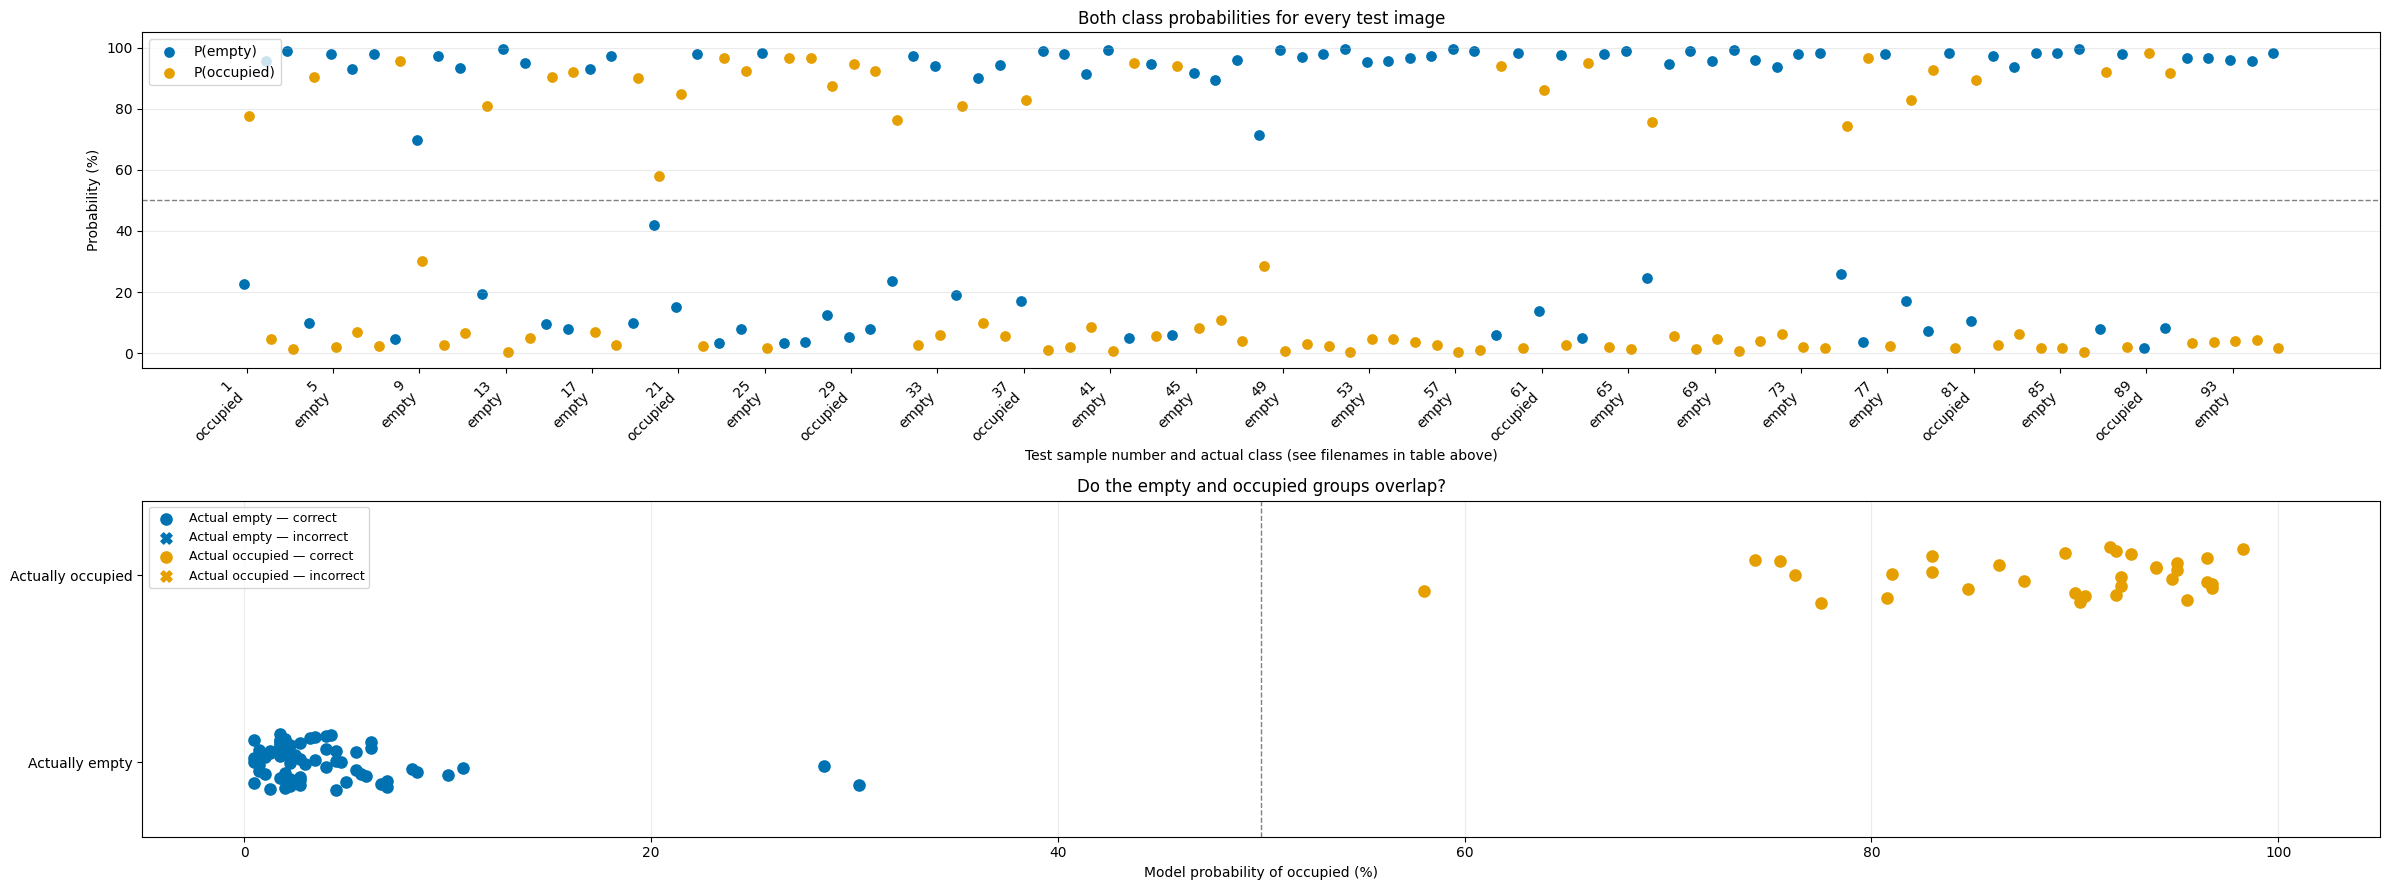

In [16]:
# Find the correct probability column by name instead of assuming its order.
probabilities = model.predict_proba(X_test)
empty_col = list(model.classes_).index("empty")
occupied_col = list(model.classes_).index("occupied")
p_empty = probabilities[:, empty_col]
p_occupied = probabilities[:, occupied_col]

# Keep a table linking each plotted sample to its image file.
results = pd.DataFrame({
    "Sample": np.arange(1, len(test_idx) + 1),
    "File": [str(df.iloc[i]["path"].relative_to(DATASET_DIR)) for i in test_idx],
    "Actual": y_test,
    "Predicted": y_pred,
    "P(empty)": p_empty,
    "P(occupied)": p_occupied,
})
print(results.to_string(index=False, formatters={
    "P(empty)": "{:.1%}".format, "P(occupied)": "{:.1%}".format,
}))

colors = {"empty": "#0072B2", "occupied": "#E69F00"}
samples = results["Sample"].to_numpy()
fig, axes = plt.subplots(2, 1, figsize=(max(10, min(24, len(samples) * 0.45)), 9))

# A pair of dots shows both probabilities for each test image.
axes[0].scatter(samples - 0.12, p_empty * 100, color=colors["empty"], label="P(empty)", s=45)
axes[0].scatter(samples + 0.12, p_occupied * 100, color=colors["occupied"], label="P(occupied)", s=45)
axes[0].axhline(50, color="gray", linestyle="--", linewidth=1)
# Limit tick labels when testing many images so the chart stays readable.
tick_step = max(1, math.ceil(len(samples) / 30))
axes[0].set_xticks(samples[::tick_step])
axes[0].set_xticklabels([f"{s}\n{a}" for s, a in zip(samples[::tick_step], y_test[::tick_step])], rotation=45, ha="right")
axes[0].set_ylim(-5, 105)
axes[0].set_xlabel("Test sample number and actual class (see filenames in table above)")
axes[0].set_ylabel("Probability (%)")
axes[0].set_title("Both class probabilities for every test image")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

# Use the SAME probability axis for both groups to reveal overlap.
for row, label in enumerate(["empty", "occupied"]):
    indices = np.flatnonzero(y_test == label)
    offsets = np.linspace(-0.15, 0.15, len(indices))
    for marker, is_correct in [("o", True), ("X", False)]:
        mask = (y_pred[indices] == y_test[indices]) == is_correct
        axes[1].scatter(p_occupied[indices][mask] * 100, row + offsets[mask],
                        color=colors[label], marker=marker, s=65,
                        label=f"Actual {label} — {'correct' if is_correct else 'incorrect'}")
axes[1].axvline(50, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlim(-5, 105)
axes[1].set_yticks([0, 1], ["Actually empty", "Actually occupied"])
axes[1].set_ylim(-0.4, 1.4)
axes[1].set_xlabel("Model probability of occupied (%)")
axes[1].set_title("Do the empty and occupied groups overlap?")
axes[1].legend(loc="best", fontsize=9)
axes[1].grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 7. Save the tested model

We save the **same model we just tested**. It is not retrained on the test images. The feature settings stay compatible with the original HOG + color classifier.


In [17]:
joblib.dump(model, MODEL_OUT)
metadata = {
    "classifier": "hog_color_random_forest",
    "classes": [str(c) for c in model.classes_],
    "feature_count": int(X.shape[1]),
    "training_images": int(len(y_train)),
    "test_images": int(len(y_test)),
    "test_accuracy": float(accuracy),
    "test_size": TEST_SIZE,
    "class_counts": {k: int(v) for k, v in pd.Series(y_train).value_counts().items()},
    "test_class_counts": {k: int(v) for k, v in pd.Series(y_test).value_counts().items()},
    "n_estimators": N_ESTIMATORS,
    "random_state": RANDOM_STATE,
    "hog_size": HOG_SIZE,
    "hog_orientations": HOG_ORIENTATIONS,
    "hog_pixels_per_cell": HOG_PIXELS_PER_CELL,
    "hog_cells_per_block": HOG_CELLS_PER_BLOCK,
}
METADATA_OUT.write_text(json.dumps(metadata, indent=2))
print(f"Saved model: {MODEL_OUT.resolve()}")
print(f"Saved metadata: {METADATA_OUT.resolve()}")


Saved model: /Volumes/media/image_classifier_rfhog/mailbox_rfhog.joblib
Saved metadata: /Volumes/media/image_classifier_rfhog/mailbox_rfhog_metadata.json


## Optional: Which features mattered most?

Each bar represents one image feature. A taller bar means the model used that feature more. These are feature numbers, not image numbers.


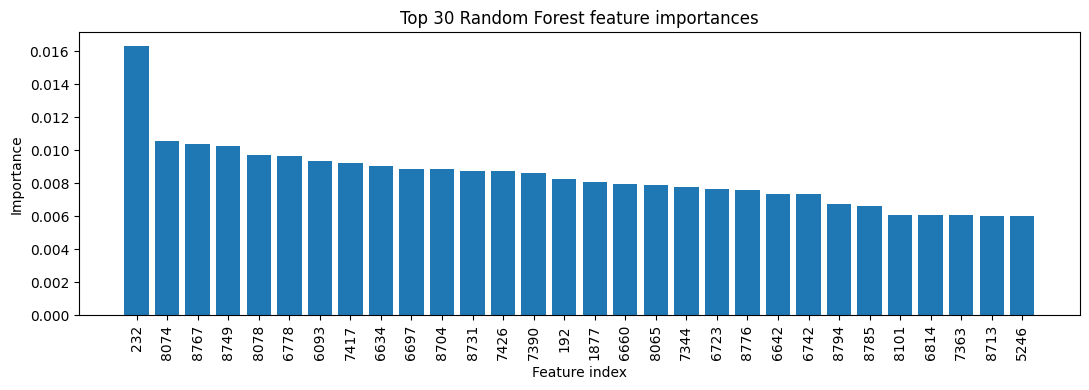

In [18]:
importances = model.feature_importances_
top_idx = np.argsort(importances)[::-1][:30]

plt.figure(figsize=(11, 4))
plt.bar(range(len(top_idx)), importances[top_idx])
plt.xticks(range(len(top_idx)), top_idx, rotation=90)
plt.xlabel("Feature index")
plt.ylabel("Importance")
plt.title("Top 30 Random Forest feature importances")
plt.tight_layout()
plt.show()


## Deploy

Copy:

```text
mailbox_rfhog.joblib
```

to:

```text
/data/mailbox_rfhog.joblib
```

inside the Home Assistant App, then restart the App or call `POST /reload`.


## This utility function can be used to determine your repo hash name
## https://developers.home-assistant.io/docs/apps/communication

In [2]:
"""Util add-ons functions."""
import hashlib
import logging
from pathlib import Path
import re

RE_SHA1 = re.compile(r"[a-f0-9]{8}")
_LOGGER: logging.Logger = logging.getLogger(__name__)


def get_hash_from_repository(name: str) -> str:
    """Generate a hash from repository."""
    key = name.lower().encode()
    return hashlib.sha1(key).hexdigest()[:8]


def extract_hash_from_path(path: Path) -> str:
    """Extract repo id from path."""
    repository_dir = path.parts[-1]

    if not RE_SHA1.match(repository_dir):
        return get_hash_from_repository(repository_dir)
    return repository_dir

repo_hash = get_hash_from_repository(
    "https://github.com/pbreuss/smart-home-rewired"
)
print(repo_hash)

32878c6d
